# DBP15K Dataset Structure

In [3]:
# base_path = 'C:\\Users\\Partiran\\Desktop\\TKG\\dbp15k'
base_path = 'dbp15k'

def parse_directory(path, n):
    print(n*'   ' + os.path.basename(path))
    if not os.path.isdir(path):
        pass
    else:
        n += 1
        for each in os.listdir(path):
            # print(each)
            
            new_path = path + '\\' + each
            parse_directory(new_path, n)


for each in os.listdir(base_path):
    path = base_path + '\\' + each
    parse_directory(path, 0)

en_all_attrs_range
fr_en
   0_1
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   0_2
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   0_3
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   0_4
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   0_5
      ent_ids_1
      ent_ids_2
      ref_ents
      ref_ent_ids
      rel_ids_1
      rel_ids_2
      sup_ent_ids
      sup_rel_ids
      triples_1
      triples_2
   all_attrs_range
   ent_ILLs
   mtranse
      0_1
         ent_ids_1
         ent_ids_2
         ref_pairs
      

## save as json

In [4]:
import os
import json

base_path = r'C:\Users\Partiran\Desktop\dbp15k'

def directory_to_dict(path):
    if os.path.isfile(path):
        return None  # file

    result = {}

    for item in os.listdir(path):
        full_path = os.path.join(path, item)

        if os.path.isdir(full_path):
            result[item] = directory_to_dict(full_path)
        else:
            result[item] = "file"

    return result

tree = {
    os.path.basename(base_path): directory_to_dict(base_path)
}

with open("directory_structure.json", "w", encoding="utf-8") as f:
    json.dump(tree, f, indent=4)

print("Saved to directory_structure.json")

Saved to directory_structure.json


# Temporal Analysis

In [10]:
import os
from collections import Counter

def analyze_temporal_facts(base_path, language_pair="fr_en", fold="0_1"):
    path = f"{base_path}/dbp15k/{language_pair}/{fold}"
    
    # Load relation mappings
    def load_rel_mapping(file_path):
        mapping = {}
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                parts = line.strip().split('\t') if '\t' in line else line.strip().split()
                if len(parts) >= 2:
                    rel_id = parts[0]
                    rel_name = parts[1]
                    mapping[rel_id] = rel_name
        return mapping
    
    rel_mapping_1 = load_rel_mapping(f"{path}/rel_ids_1")
    rel_mapping_2 = load_rel_mapping(f"{path}/rel_ids_2")
    
    temporal_keywords = ["date", "naissance", "décès", "birth", "death", "start", "end", 
                         "création", "période", "année", "début", "fin", "fondation"]
    
    total_triples = 0
    temporal_triples = 0
    temporal_rels = Counter()
    
    for kg in ['triples_1', 'triples_2']:
        file_path = f"{path}/{kg}"
        if not os.path.exists(file_path):
            continue
            
        mapping = rel_mapping_1 if kg == 'triples_1' else rel_mapping_2
        
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                total_triples += 1
                parts = line.strip().split()
                if len(parts) >= 3:
                    rel_id = parts[1]
                    rel_name = mapping.get(rel_id, f"ID_{rel_id}")
                    
                    rel_lower = rel_name.lower()
                    if any(kw in rel_lower for kw in temporal_keywords):
                        temporal_triples += 1
                        temporal_rels[rel_name] += 1
    
    percentage = (temporal_triples / total_triples * 100) if total_triples > 0 else 0
    
    print(f"=== TEMPORAL ANALYSIS: {language_pair} / {fold} ===")
    print(f"Total Triples     : {total_triples:,}")
    print(f"Temporal Triples  : {temporal_triples:,}")
    print(f"Percentage        : {percentage:.3f}%")
    print("\nTop Temporal Relations:")
    for rel, count in temporal_rels.most_common(15):
        print(f"  {rel:<40} : {count:,}")
    
    return percentage

# Run it
if __name__ == "__main__":
    base_path = r"C:\Users\Partiran\Desktop"
    analyze_temporal_facts(base_path, language_pair="fr_en", fold="0_1")

=== TEMPORAL ANALYSIS: fr_en / 0_1 ===
Total Triples     : 221,720
Temporal Triples  : 13,777
Percentage        : 6.214%

Top Temporal Relations:
  http://dbpedia.org/property/birthPlace   : 5,799
  http://fr.dbpedia.org/property/lieuDeNaissance : 2,499
  http://dbpedia.org/property/deathPlace   : 2,247
  http://fr.dbpedia.org/property/lieuDeDécès : 1,201
  http://dbpedia.org/property/placeOfBirth : 823
  http://dbpedia.org/property/placeOfDeath : 221
  http://fr.dbpedia.org/property/lieuNaissance : 177
  http://dbpedia.org/property/birthplace   : 122
  http://fr.dbpedia.org/property/fondateur : 86
  http://fr.dbpedia.org/property/reléguéFin : 78
  http://fr.dbpedia.org/property/paysDeNaissance : 76
  http://fr.dbpedia.org/property/promuDébut : 67
  http://fr.dbpedia.org/property/paysDeDécès : 47
  http://fr.dbpedia.org/property/débuts    : 32
  http://fr.dbpedia.org/property/finaliste : 29


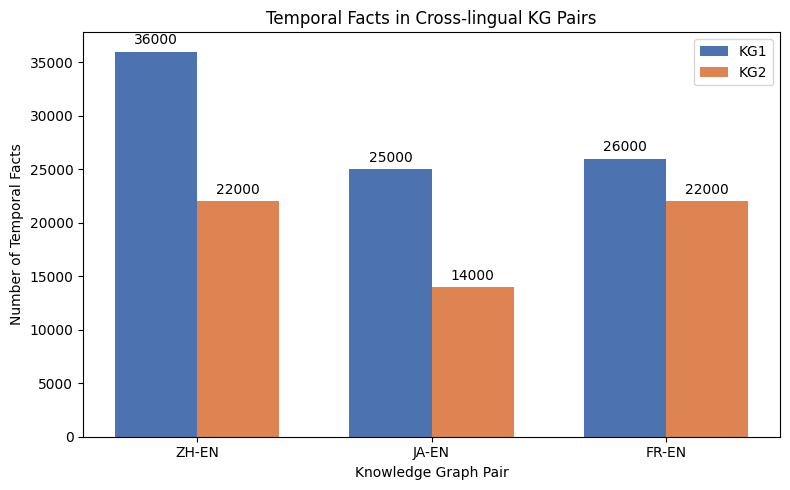

In [3]:
import numpy as np
import matplotlib.pyplot as plt

pairs = ['ZH-EN', 'JA-EN', 'FR-EN']

# #Time values
kg1 = [36000, 25000, 26000]
kg2 = [22000, 14000, 22000]

x = np.arange(len(pairs))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(
    x - width/2,
    kg1,
    width,
    label='KG1',
    color='#4C72B0'   # blue
)

bars2 = plt.bar(
    x + width/2,
    kg2,
    width,
    label='KG2',
    color='#DD8452'   # orange
)

plt.xticks(x, pairs)
plt.ylabel('Number of Temporal Facts')
plt.xlabel('Knowledge Graph Pair')
plt.title('Temporal Facts in Cross-lingual KG Pairs')
plt.legend()

# Value labels
for bars in [bars1, bars2]:
    plt.bar_label(bars, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

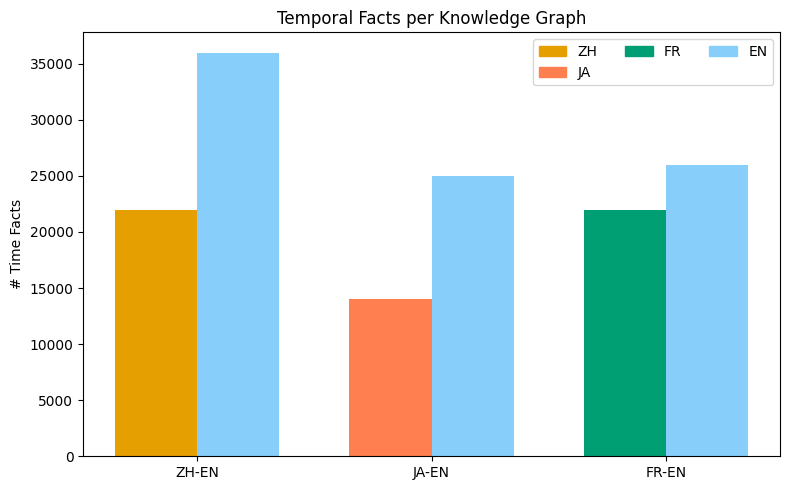

In [13]:
import numpy as np
import matplotlib.pyplot as plt

colors = {
    'ZH': '#E69F00',   # orange
    'JA': '#56B4E9',   # light blue
    'FR': '#009E73',   # green
    'EN': '#0072B2',   # dark blue
    'DBP': '#CC79A7',  # purple
    'WD': '#D55E00'    # vermillion
}

pairs = ['ZH-EN', 'JA-EN', 'FR-EN']

left_labels  = ['ZH', 'JA', 'FR']
right_labels = ['EN', 'EN', 'EN']

# left_values  = [36000, 25000, 26000]
# right_values = [22000, 14000, 22000]

left_values  = [22000, 14000, 22000]
right_values = [36000, 25000, 26000]

x = np.arange(len(pairs))
width = 0.35

colors = {
    'ZH': '#E69F00',
    # 'JA': '#56B4E9',
    'JA': 'coral',
    'FR': '#009E73',
    # 'EN': '#0072B2',
    'EN': 'lightskyblue'
}

fig, ax = plt.subplots(figsize=(8,5))

for i in range(len(pairs)):
    ax.bar(
        x[i] - width/2,
        left_values[i],
        width,
        color=colors[left_labels[i]]
    )

    ax.bar(
        x[i] + width/2,
        right_values[i],
        width,
        color=colors[right_labels[i]]
    )

ax.set_xticks(x)
ax.set_xticklabels(pairs)
ax.set_ylabel('# Time Facts')
ax.set_title('Temporal Facts per Knowledge Graph')

# Custom legend
handles = [
    plt.Rectangle((0,0),1,1,color=colors['ZH']),
    plt.Rectangle((0,0),1,1,color=colors['JA']),
    plt.Rectangle((0,0),1,1,color=colors['FR']),
    plt.Rectangle((0,0),1,1,color=colors['EN']),
]

ax.legend(handles,
          ['ZH','JA','FR','EN'],
          ncol=3)

plt.tight_layout()
plt.show()

# DBPT15K

## Dataset Structure

In [2]:
import os 

base_path = r'D:\Proposal\Temporal Reasoning\TKG\EACTB-main\EACTB-main\dbp15k'
                    
def parse_directory(path, n):
    print(n*'   ' + os.path.basename(path))
    if not os.path.isdir(path):
        pass
    else:
        n += 1
        for each in os.listdir(path):
            # print(each)
            
            new_path = path + '\\' + each
            parse_directory(new_path, n)


for each in os.listdir(base_path):
    path = base_path + '\\' + each
    parse_directory(path, 0)

fr_en
   comment_1
   comment_2
   dev
   ent_ids_1
   ent_ids_2
   ref_ent_ids
   test
   time_id
   train
   training_attrs_1
   training_attrs_2
   triples_1
   triples_2
ja_en
   comment_1
   comment_2
   dev
   ent_ids_1
   ent_ids_2
   ref_ent_ids
   test
   time_id
   train
   training_attrs_1
   training_attrs_2
   triples_1
   triples_2
zh_en
   comment_1
   comment_2
   dev
   ent_ids_1
   ent_ids_2
   ref_ent_ids
   test
   time_id
   train
   training_attrs_1
   training_attrs_2
   triples_1
   triples_2


# General Analysis

In [7]:
"""
Step 1: Basic counts for a KG alignment pair (e.g. fr_en, ja_en, zh_en)

For each pair, we read:
    triples_1     -> the facts of KG1 (e.g. French), as quadruples (h, r, t, timestamp)
    triples_2     -> the facts of KG2 (e.g. English), as quadruples (h, r, t, timestamp)
    ent_ids_1     -> the full list of entity ids that exist in KG1 (includes isolated ones)
    ent_ids_2     -> the full list of entity ids that exist in KG2 (includes isolated ones)
    ref_ent_ids   -> the gold-standard alignment links between KG1 and KG2

And we count:
    - number of entities in KG1 and KG2 (exact, from ent_ids_1 / ent_ids_2)
    - number of relations in KG1 and KG2 (from the triples)
    - number of facts (triples) in KG1 and KG2
    - number of alignment links
"""

import os

# Edit these to match your setup.
DATA_ROOT = r'D:\Proposal\Temporal Reasoning\TKG\EACTB-main\EACTB-main\dbp15k'  # change to your actual path
PAIRS = ["fr_en", "ja_en", "zh_en"]
TITLES = {
    "fr_en": "DBP15K (EN-FR)",
    "ja_en": "DBP15K (EN-JA)",
    "zh_en": "DBP15K (EN-ZH)",
}


def read_triples(path):
    """
    Read a triples file. Each line is a QUADRUPLE: head_id, relation_id, tail_id, timestamp_id.
    Returns a list of (head, relation, tail, timestamp) tuples.
    """
    triples = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split("\t")
            if len(parts) < 4:
                continue
            h, r, t, time = parts[0], parts[1], parts[2], parts[3]
            triples.append((h, r, t, time))
    return triples


def read_id_pairs(path):
    """
    Read a two-column file of ids, one pair per line.
    Used for ref_ent_ids (KG1_entity_id -> KG2_entity_id).
    Returns a list of (col1, col2) tuples.
    """
    pairs = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split("\t")
            if len(parts) < 2:
                continue
            pairs.append((parts[0], parts[1]))
    return pairs


def read_entity_ids(path):
    """
    Read ent_ids_1 or ent_ids_2: entity_id \t entity_uri, one line per entity
    that EXISTS in the KG -- including entities with zero triples (isolated nodes).
    Returns a set of entity ids.
    """
    entities = set()
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split("\t")
            if len(parts) < 2:
                continue
            entities.add(parts[0])
    return entities


def count_entities_and_relations(triples):
    """
    Given a list of (head, relation, tail, timestamp) quadruples, return the
    set of distinct entities and the set of distinct relations.
    """
    entities = set()
    relations = set()
    for h, r, t, time in triples:
        entities.add(h)
        entities.add(t)
        relations.add(r)
    return entities, relations


def analyze_pair(folder, title=None):
    folder = folder.rstrip("/").rstrip("\\")
    if title is None:
        title = os.path.basename(folder)

    triples_1 = read_triples(os.path.join(folder, "triples_1"))
    triples_2 = read_triples(os.path.join(folder, "triples_2"))
    alignment_links = read_id_pairs(os.path.join(folder, "ref_ent_ids"))

    entities_1 = read_entity_ids(os.path.join(folder, "ent_ids_1"))
    entities_2 = read_entity_ids(os.path.join(folder, "ent_ids_2"))

    _, relations_1 = count_entities_and_relations(triples_1)
    _, relations_2 = count_entities_and_relations(triples_2)

    print(f"\n===== {title} =====")
    print(f"KG1: {len(entities_1)} entities | {len(relations_1)} relations | {len(triples_1)} facts")
    print(f"KG2: {len(entities_2)} entities | {len(relations_2)} relations | {len(triples_2)} facts")
    print(f"Alignment links (KG1 <-> KG2): {len(alignment_links)}")


if __name__ == "__main__":
    for pair in PAIRS:
        folder_path = os.path.join(DATA_ROOT, pair)
        title = TITLES.get(pair, pair)
        analyze_pair(folder_path, title)


===== DBP15K (EN-FR) =====
KG1: 19661 entities | 903 relations | 105998 facts
KG2: 19993 entities | 1208 relations | 115722 facts
Alignment links (KG1 <-> KG2): 15000

===== DBP15K (EN-JA) =====
KG1: 19814 entities | 1299 relations | 77214 facts
KG2: 19780 entities | 1153 relations | 93484 facts
Alignment links (KG1 <-> KG2): 15000

===== DBP15K (EN-ZH) =====
KG1: 19388 entities | 1701 relations | 70414 facts
KG2: 19572 entities | 1323 relations | 95142 facts
Alignment links (KG1 <-> KG2): 15000


# Calculate degree distribution

Loaded: triples_1
Loaded: triples_2
Loaded: training_attrs_1
Loaded: training_attrs_2

=== Degree Distribution for fr_en (Temporal) ===
Number of entities     : 70849
Average degree         : 7.10
Median degree          : 2.00
Max degree             : 4878
Min degree             : 1

Top 10 most common degrees:
  Degree   1:  34883 entities
  Degree   2:   2859 entities
  Degree   8:   2591 entities
  Degree   7:   2464 entities
  Degree   9:   2463 entities
  Degree   6:   2319 entities
  Degree  10:   2237 entities
  Degree   5:   2183 entities
  Degree   3:   2138 entities
  Degree  11:   2040 entities

Plot saved as: degree_distribution_fr_en_temporal.png
Loaded: triples_1
Loaded: triples_2
Loaded: training_attrs_1
Loaded: training_attrs_2

=== Degree Distribution for zh_en (Temporal) ===
Number of entities     : 70703
Average degree         : 5.53
Median degree          : 1.00
Max degree             : 1181
Min degree             : 1

Top 10 most common degrees:
  Degree   1:  3650

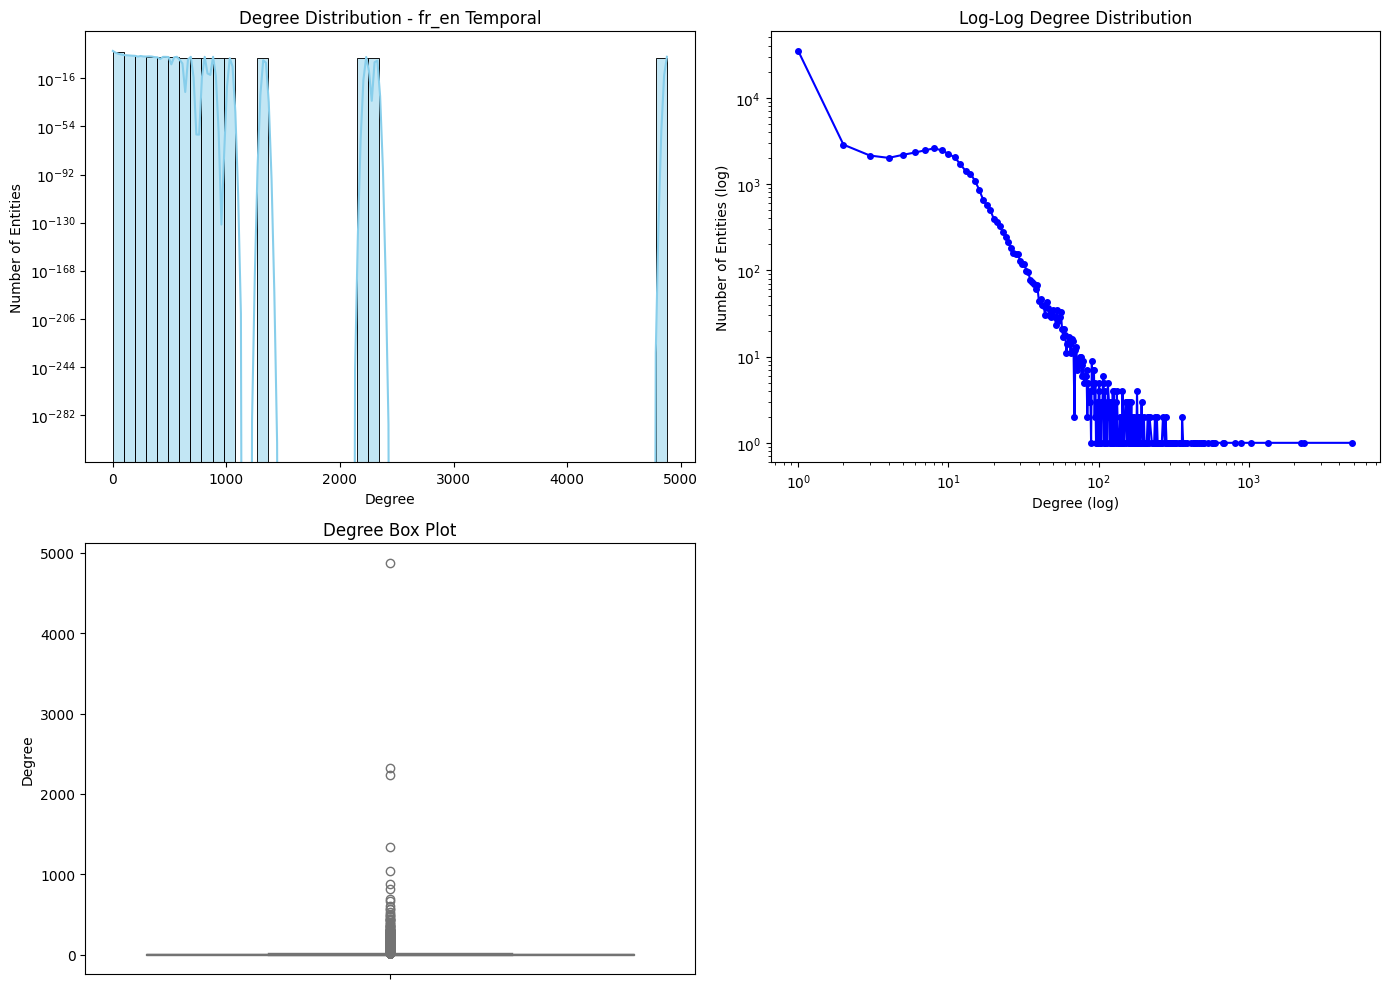

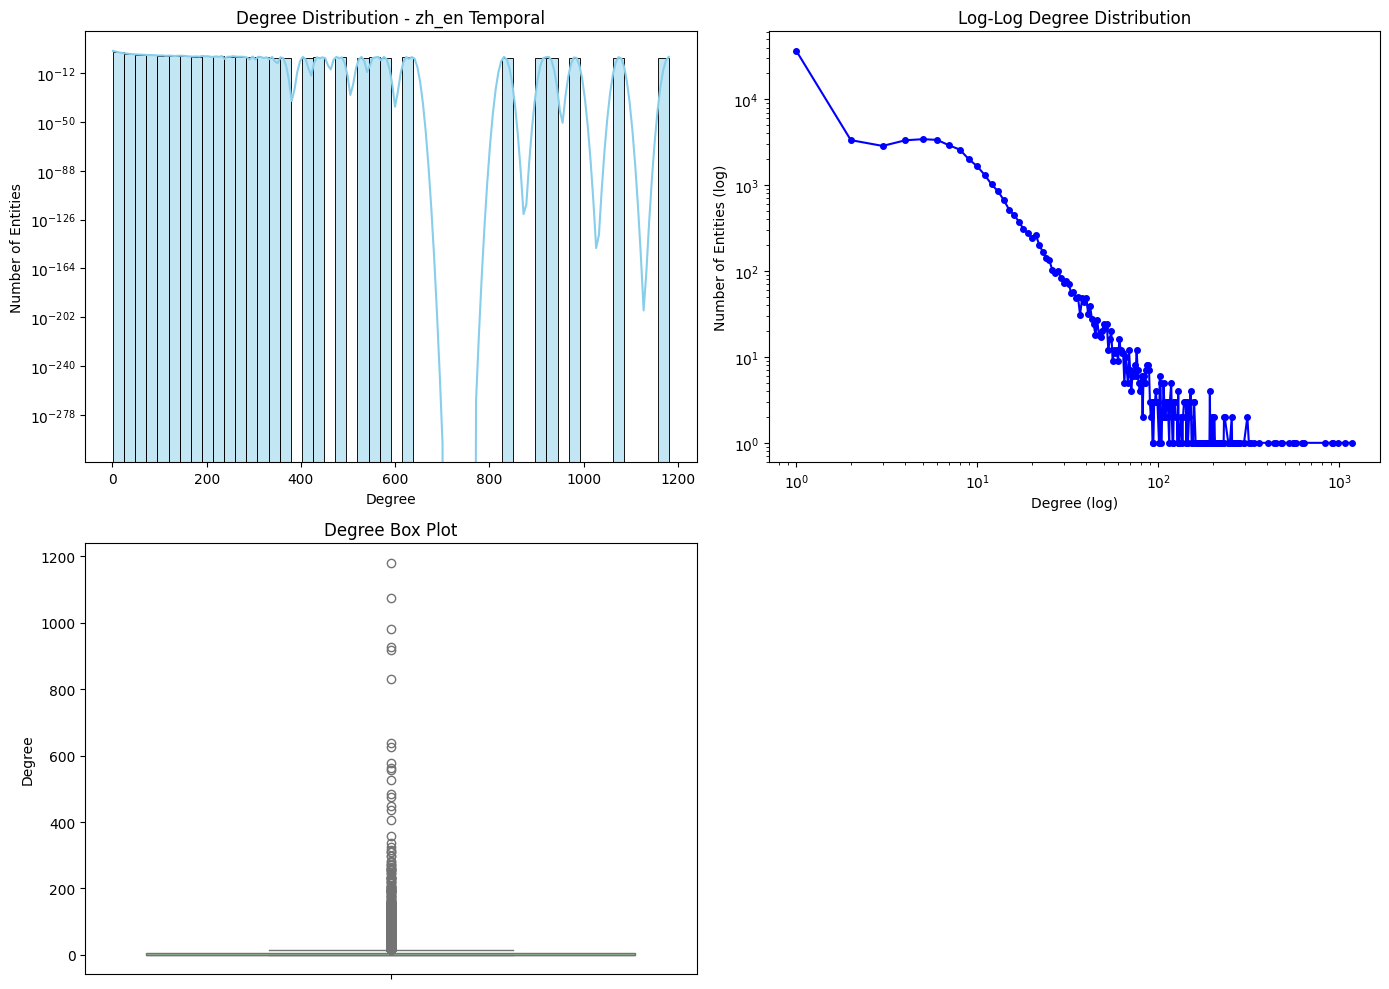

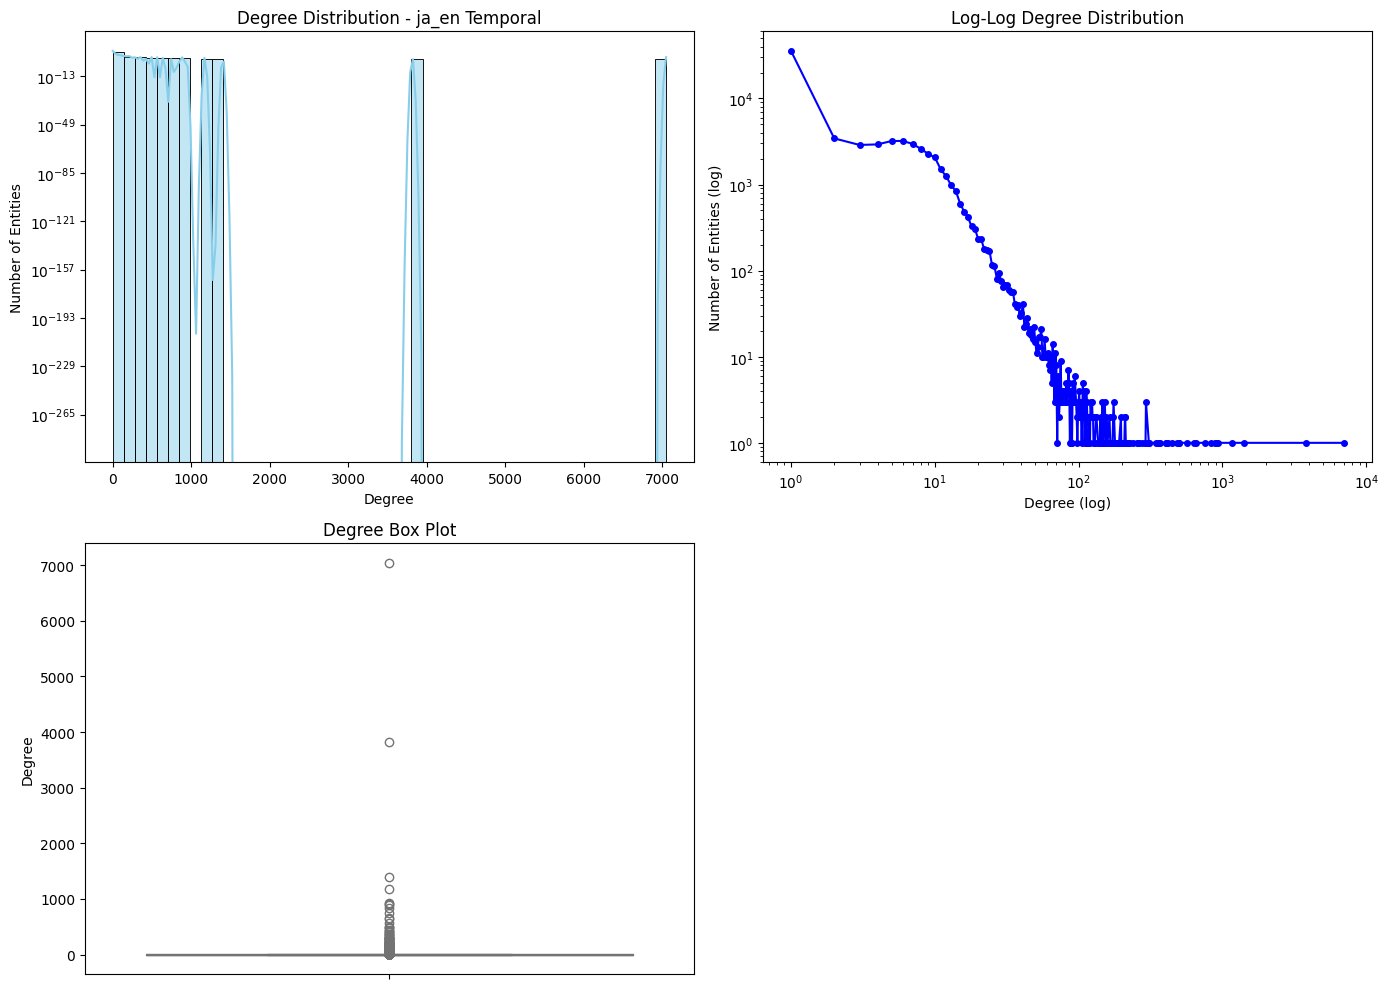

In [1]:
from collections import defaultdict, Counter
import statistics
import matplotlib.pyplot as plt
import seaborn as sns
import os

def calculate_temporal_degree(base_path, language_pair="fr_en"):
    path = f"{base_path}/{language_pair}"
    
    out_degree = defaultdict(int)
    in_degree = defaultdict(int)
    
    # Load all possible triple/attribute files
    files_to_check = ["triples_1", "triples_2", "training_attrs_1", "training_attrs_2"]
    
    loaded = False
    for filename in files_to_check:
        file_path = f"{path}/{filename}"
        if os.path.exists(file_path):
            with open(file_path, 'r', encoding='utf-8') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 3:
                        h = parts[0]
                        t = parts[2] if len(parts) > 2 else parts[1]
                        out_degree[h] += 1
                        in_degree[t] += 1
            print(f"Loaded: {filename}")
            loaded = True
    
    if not loaded:
        print("No triple files found!")
        return None, None
    
    total_degree = {e: out_degree[e] + in_degree[e] for e in set(out_degree) | set(in_degree)}
    degrees = list(total_degree.values())
    
    print(f"\n=== Degree Distribution for {language_pair} (Temporal) ===")
    print(f"Number of entities     : {len(degrees)}")
    print(f"Average degree         : {statistics.mean(degrees):.2f}")
    print(f"Median degree          : {statistics.median(degrees):.2f}")
    print(f"Max degree             : {max(degrees)}")
    print(f"Min degree             : {min(degrees)}")
    
    # Degree distribution
    dist = Counter(degrees)
    print("\nTop 10 most common degrees:")
    for deg, count in sorted(dist.items(), key=lambda x: -x[1])[:10]:
        print(f"  Degree {deg:3d}: {count:6d} entities")
    
    # === Visualization ===
    plt.figure(figsize=(14, 10))
    
    plt.subplot(2, 2, 1)
    sns.histplot(degrees, bins=50, kde=True, color='skyblue')
    plt.title(f'Degree Distribution - {language_pair} Temporal')
    plt.xlabel('Degree')
    plt.ylabel('Number of Entities')
    plt.yscale('log')
    
    plt.subplot(2, 2, 2)
    degs, counts = zip(*sorted(dist.items()))
    plt.loglog(degs, counts, 'bo-', markersize=4)
    plt.title('Log-Log Degree Distribution')
    plt.xlabel('Degree (log)')
    plt.ylabel('Number of Entities (log)')
    
    plt.subplot(2, 2, 3)
    sns.boxplot(y=degrees, color='lightgreen')
    plt.title('Degree Box Plot')
    plt.ylabel('Degree')
    
    plt.tight_layout()
    save_path = f'degree_distribution_{language_pair}_temporal.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\nPlot saved as: {save_path}")
    
    return degrees, dist

# Run for all language pairs
base = r'D:\Proposal\Temporal Reasoning\TKG\EACTB-main\EACTB-main\dbp15k'
for lang in ["fr_en", "zh_en", "ja_en"]:
    calculate_temporal_degree(base, lang)

Saved: degree_fr_en_side1.png
Saved: degree_fr_en_side2.png

Completed for fr_en
Saved: degree_zh_en_side1.png
Saved: degree_zh_en_side2.png

Completed for zh_en
Saved: degree_ja_en_side1.png
Saved: degree_ja_en_side2.png

Completed for ja_en


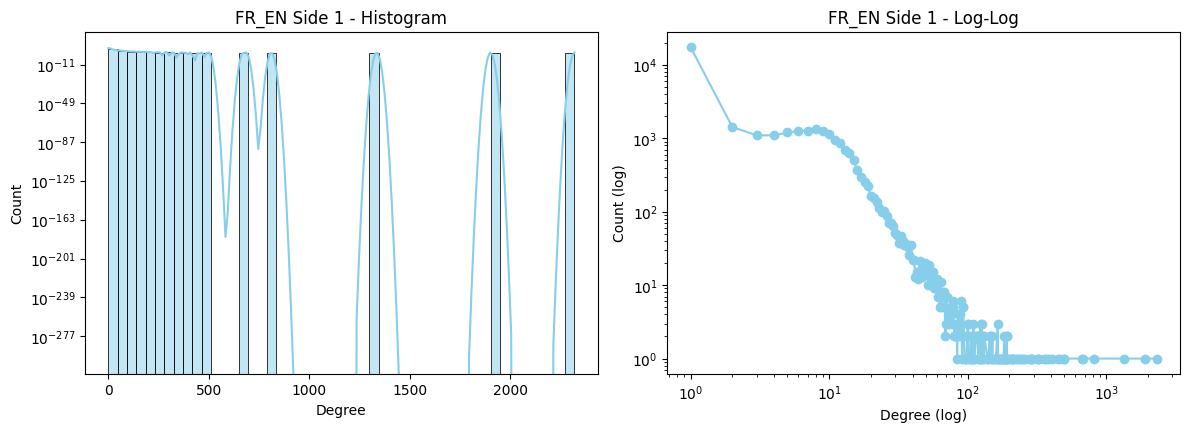

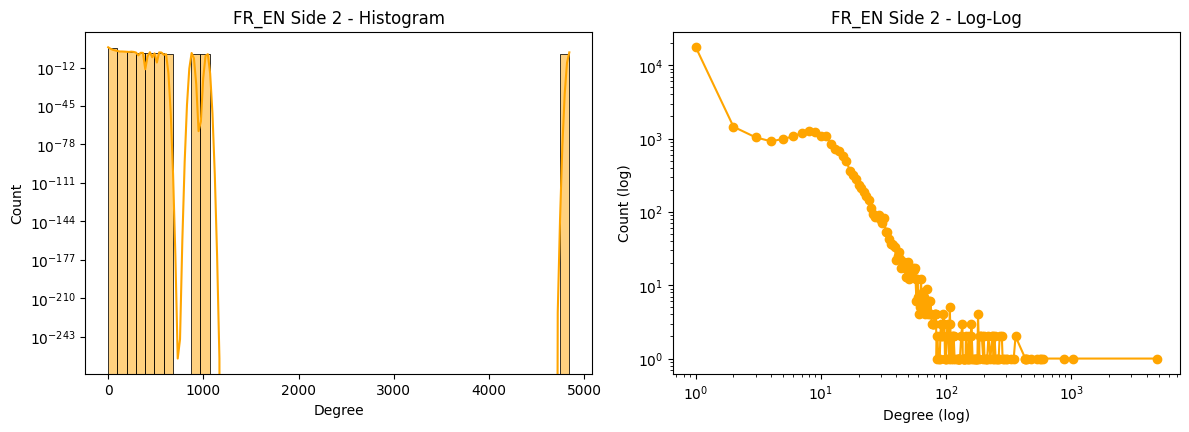

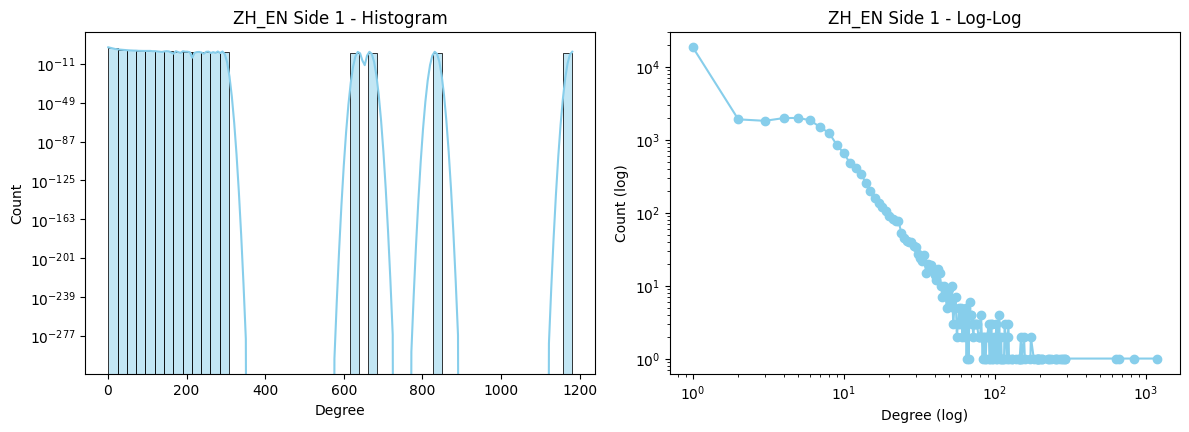

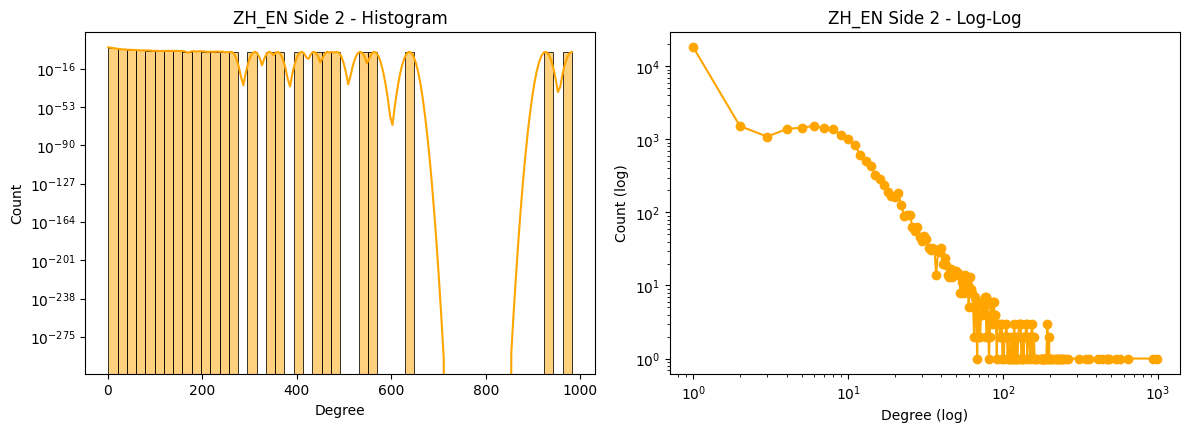

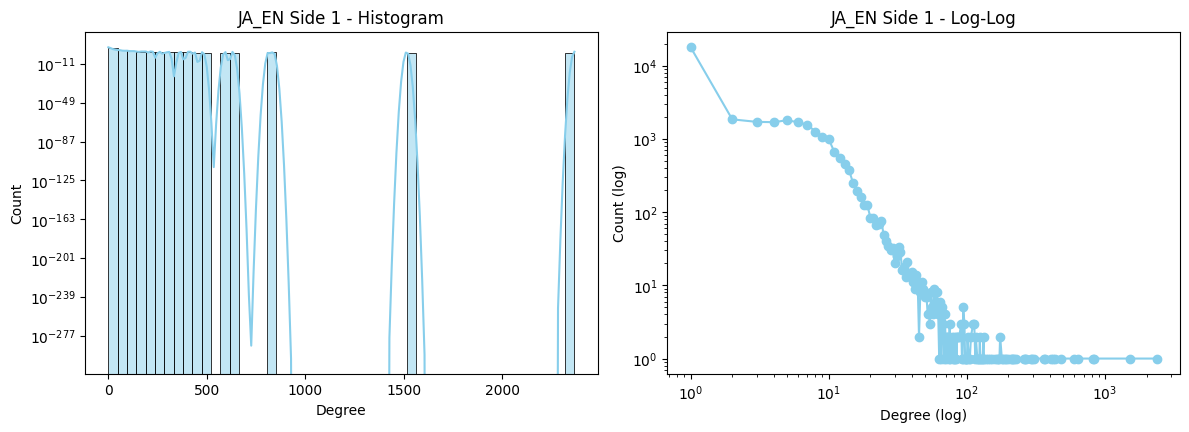

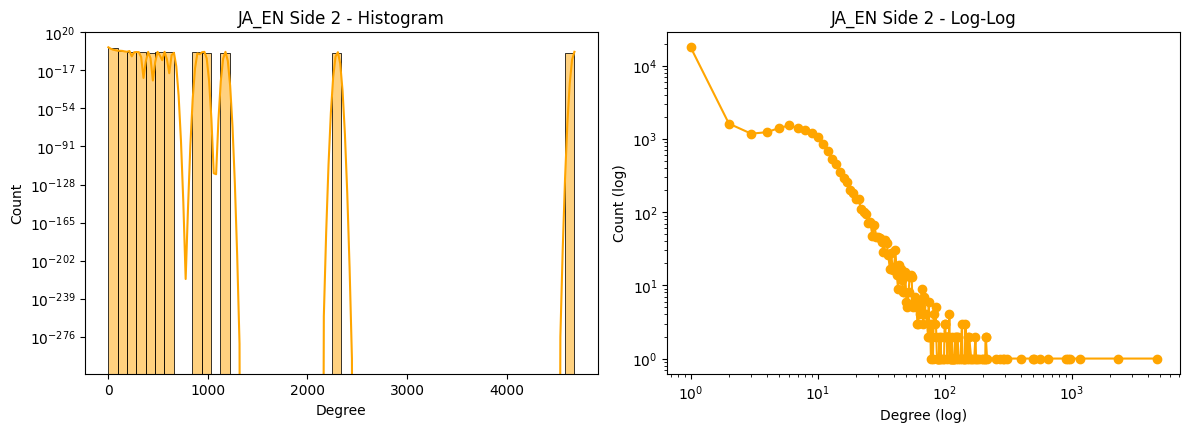

In [2]:
from collections import defaultdict, Counter
import statistics
import matplotlib.pyplot as plt
import seaborn as sns
import os

def plot_degree_per_side(base_path, language_pair="fr_en"):
    path = f"{base_path}/{language_pair}"
    
    def load_degrees(side):
        out_d = defaultdict(int)
        in_d = defaultdict(int)
        for ftype in ["triples", "training_attrs"]:
            for s in [side]:
                file_path = f"{path}/{ftype}_{s}"
                if os.path.exists(file_path):
                    with open(file_path, 'r', encoding='utf-8') as f:
                        for line in f:
                            parts = line.strip().split()
                            if len(parts) >= 3:
                                h = parts[0]
                                t = parts[2] if len(parts) > 2 else parts[1]
                                out_d[h] += 1
                                in_d[t] += 1
        total = {e: out_d[e] + in_d[e] for e in set(out_d) | set(in_d)}
        return list(total.values())
    
    # Side 1 and Side 2
    deg1 = load_degrees(1)   # e.g., French
    deg2 = load_degrees(2)   # e.g., English
    
    def plot_dist(degrees, title, color, save_name):
        plt.figure(figsize=(12, 8))
        
        plt.subplot(2, 2, 1)
        sns.histplot(degrees, bins=50, kde=True, color=color)
        plt.title(f'{title} - Histogram')
        plt.xlabel('Degree')
        plt.ylabel('Count')
        plt.yscale('log')
        
        plt.subplot(2, 2, 2)
        dist = Counter(degrees)
        degs, counts = zip(*sorted(dist.items()))
        plt.loglog(degs, counts, 'o-', color=color)
        plt.title(f'{title} - Log-Log')
        plt.xlabel('Degree (log)')
        plt.ylabel('Count (log)')
        
        plt.tight_layout()
        plt.savefig(save_name, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_name}")
    
    plot_dist(deg1, f"{language_pair.upper()} Side 1", 'skyblue', f'degree_{language_pair}_side1.png')
    plot_dist(deg2, f"{language_pair.upper()} Side 2", 'orange', f'degree_{language_pair}_side2.png')
    
    print(f"\nCompleted for {language_pair}")

# Run for all pairs
base = r'D:\Proposal\Temporal Reasoning\TKG\EACTB-main\EACTB-main\dbp15k'
for lang in ["fr_en", "zh_en", "ja_en"]:
    plot_degree_per_side(base, lang)

In [3]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
import seaborn as sns
import os

def plot_combined_degree(base_path=r'D:\Proposal\Temporal Reasoning\TKG\EACTB-main\EACTB-main\dbp15k', language_pair="fr_en"):
    path = f"{base_path}/{language_pair}"
    
    def load_degrees(side):
        out_d = defaultdict(int)
        in_d = defaultdict(int)
        for ftype in ["triples", "training_attrs"]:
            file_path = f"{path}/{ftype}_{side}"
            if os.path.exists(file_path):
                with open(file_path, 'r', encoding='utf-8') as f:
                    for line in f:
                        parts = line.strip().split()
                        if len(parts) >= 3:
                            h = parts[0]
                            t = parts[2] if len(parts) > 2 else parts[1]
                            out_d[h] += 1
                            in_d[t] += 1
        total = {e: out_d[e] + in_d[e] for e in set(out_d) | set(in_d)}
        return list(total.values())
    
    deg1 = load_degrees(1)   # Side 1 (e.g. FR)
    deg2 = load_degrees(2)   # Side 2 (e.g. EN)
    
    # Create combined plot like your example
    plt.figure(figsize=(10, 6))
    
    # Histogram with two languages
    sns.histplot(deg1, bins=20, kde=False, color='blue', alpha=0.7, label='Side 1 (FR)', stat='percent')
    sns.histplot(deg2, bins=20, kde=False, color='orange', alpha=0.7, label='Side 2 (EN)', stat='percent')
    
    plt.title(f'Degree Distribution - {language_pair.upper()}')
    plt.xlabel('Degree')
    plt.ylabel('Percentage of Entities (%)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Save
    save_path = f'degree_distribution_{language_pair}_combined.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    print(f"Saved combined plot: {save_path}")
    
    # Basic stats
    print(f"\n{language_pair.upper()} Stats:")
    print(f"Side 1 Avg degree: {sum(deg1)/len(deg1):.2f}")
    print(f"Side 2 Avg degree: {sum(deg2)/len(deg2):.2f}")

# Run for all three pairs
for lang in ["fr_en", "zh_en", "ja_en"]:
    plot_combined_degree(language_pair=lang)

Saved combined plot: degree_distribution_fr_en_combined.png

FR_EN Stats:
Side 1 Avg degree: 6.87
Side 2 Avg degree: 7.33
Saved combined plot: degree_distribution_zh_en_combined.png

ZH_EN Stats:
Side 1 Avg degree: 4.79
Side 2 Avg degree: 6.19
Saved combined plot: degree_distribution_ja_en_combined.png

JA_EN Stats:
Side 1 Avg degree: 5.19
Side 2 Avg degree: 6.13


Saved → degree_distribution.png


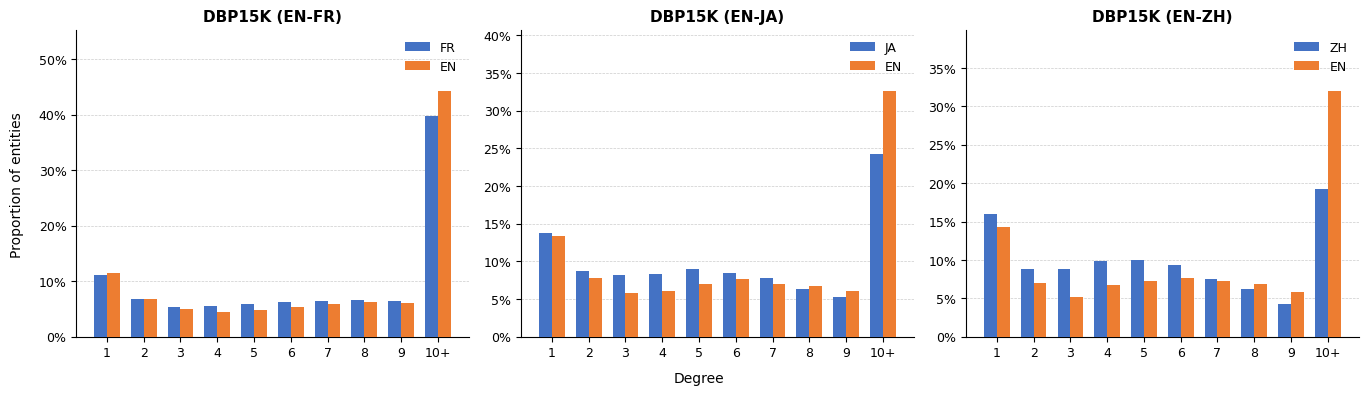

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from collections import defaultdict

# ── CONFIG ────────────────────────────────────────────────────────────────────
DATA_ROOT = r'D:\Proposal\Temporal Reasoning\TKG\EACTB-main\EACTB-main\dbp15k'         # change to your actual path
PAIRS     = ["fr_en", "ja_en", "zh_en"]
TITLES    = {
    "fr_en": "DBP15K (EN-FR)",
    "ja_en": "DBP15K (EN-JA)",
    "zh_en": "DBP15K (EN-ZH)",
}
MAX_DEGREE_SHOWN = 10           # degrees 1-9 shown individually, 10+ grouped
# ─────────────────────────────────────────────────────────────────────────────


def load_triples(filepath):
    """
    Read triples/quadruples file. Each line is:
      head  rel  tail          (3 integers)  or
      head  rel  tail  t       (4 integers)  or
      head  rel  tail  tb  te  (5 integers)
    Returns list of (head, tail) pairs.
    """
    edges = []
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 3:
                head, tail = int(parts[0]), int(parts[2])
                edges.append((head, tail))
    return edges


def compute_degree_distribution(edges, max_shown=10):
    """
    Returns a dict: degree_bucket -> fraction_of_nodes (as percentage).
    Buckets are 1, 2, ..., max_shown-1, and max_shown (meaning >= max_shown).
    """
    degree = defaultdict(int)
    for h, t in edges:
        degree[h] += 1
        degree[t] += 1

    counts = defaultdict(int)
    for d in degree.values():
        bucket = d if d < max_shown else max_shown
        counts[bucket] += 1

    total = sum(counts.values())
    distribution = {}
    for b in range(1, max_shown + 1):
        distribution[b] = (counts.get(b, 0) / total) * 100
    return distribution


def plot_degree_distributions(data_root, pairs, titles, max_shown=10):
    n_pairs = len(pairs)
    fig, axes = plt.subplots(1, n_pairs, figsize=(4.5 * n_pairs, 3.8))

    if n_pairs == 1:
        axes = [axes]

    x     = np.arange(1, max_shown + 1)
    width = 0.35

    # Colors matching the reference image (blue for KG1, orange for KG2)
    color1 = "#4472C4"   # blue  – language 1 (FR / JA / ZH)
    color2 = "#ED7D31"   # orange – EN

    for ax, pair in zip(axes, pairs):
        lang1, lang2 = pair.split("_")   # e.g. "fr", "en"

        triples1_path = os.path.join(data_root, pair, "triples_1")
        triples2_path = os.path.join(data_root, pair, "triples_2")

        edges1 = load_triples(triples1_path)
        edges2 = load_triples(triples2_path)

        dist1 = compute_degree_distribution(edges1, max_shown)
        dist2 = compute_degree_distribution(edges2, max_shown)

        vals1 = [dist1[b] for b in range(1, max_shown + 1)]
        vals2 = [dist2[b] for b in range(1, max_shown + 1)]

        bars1 = ax.bar(x - width / 2, vals1, width,
                       label=lang1.upper(), color=color1, zorder=3)
        bars2 = ax.bar(x + width / 2, vals2, width,
                       label=lang2.upper(), color=color2, zorder=3)

        # x-axis labels: 1-9 as numbers, last bucket as "10+"
        x_labels = [str(i) for i in range(1, max_shown)] + [f"{max_shown}+"]
        ax.set_xticks(x)
        ax.set_xticklabels(x_labels, fontsize=9)

        # y-axis as percentage
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
        ax.set_ylim(0, max(max(vals1), max(vals2)) * 1.25)
        ax.tick_params(axis="y", labelsize=9)

        # Light horizontal gridlines
        ax.yaxis.grid(True, linestyle="--", linewidth=0.5,
                      color="#cccccc", zorder=0)
        ax.set_axisbelow(True)

        # Remove top/right spines for cleaner look
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.set_title(titles[pair], fontsize=11, fontweight="bold", pad=6)
        ax.legend(fontsize=9, frameon=False)

    fig.text(0.5, -0.02, "Degree", ha="center", fontsize=10)
    fig.text(-0.01, 0.5, "Proportion of entities",
             va="center", rotation="vertical", fontsize=10)

    plt.tight_layout()
    plt.savefig("degree_distribution.png", dpi=150,
                bbox_inches="tight", facecolor="white")
    print("Saved → degree_distribution.png")
    plt.show()


if __name__ == "__main__":
    plot_degree_distributions(DATA_ROOT, PAIRS, TITLES, MAX_DEGREE_SHOWN)

Saved -> dbp15k_time_distribution.png


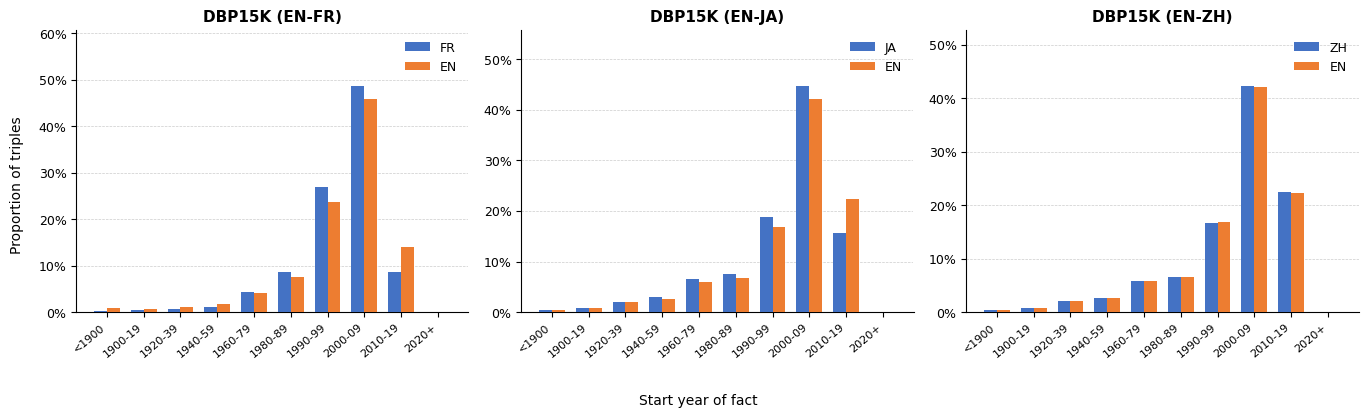

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── CONFIG ────────────────────────────────────────────────────────────────────
DATA_ROOT = r"D:\Proposal\Temporal Reasoning\TKG\EACTB-main\EACTB-main\dbp15k"  # change to your actual path
PAIRS     = ["fr_en", "ja_en", "zh_en"]
TITLES    = {
    "fr_en": "DBP15K (EN-FR)",
    "ja_en": "DBP15K (EN-JA)",
    "zh_en": "DBP15K (EN-ZH)",
}

# Decade-ish bins. A "<1900" catch-all handles the ancient tail (some facts
# go back to year 1 / 19), and a "2020+" catch-all absorbs a handful of far
# future/outlier timestamps seen in the time_id table (e.g. 2808, 19311) so
# they don't stretch the axis into uselessness.
BIN_EDGES  = [-1, 1900, 1920, 1940, 1960, 1980, 1990, 2000, 2010, 2020, 999999]
BIN_LABELS = ["<1900", "1900-19", "1920-39", "1940-59", "1960-79",
              "1980-89", "1990-99", "2000-09", "2010-19", "2020+"]
# ─────────────────────────────────────────────────────────────────────────────


def load_time_id_map(filepath):
    """
    Reads a time_id file (id \t year_or_-inf) and returns {id: year_int or None}.
    id -> None means 'unknown/unspecified' (the '-inf' row, always id 0 in
    this format) and such rows are excluded from the distribution rather
    than binned as a fake year.
    """
    year_map = {}
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) != 2:
                continue
            idx, val = parts
            idx = int(idx)
            year_map[idx] = None if val == "-inf" else int(val)
    return year_map


def load_begin_years(triples_path, year_map):
    """
    Reads a triples_1/triples_2 file: head_id rel_id tail_id begin_id end_id
    (tab-separated, 5 columns). Returns the list of resolved begin years,
    dropping rows whose begin_id maps to 'unknown' (id 0 / '-inf').
    """
    df = pd.read_csv(
        triples_path, sep="\t", header=None,
        names=["head", "rel", "tail", "begin_id", "end_id"],
    )
    years = df["begin_id"].map(year_map)
    return years.dropna().astype(int).tolist()


def compute_time_distribution(years, bin_edges, bin_labels):
    if not years:
        return {label: 0.0 for label in bin_labels}
    cats = pd.cut(pd.Series(years), bins=bin_edges, labels=bin_labels)
    counts = cats.value_counts().reindex(bin_labels, fill_value=0)
    total = counts.sum()
    return {label: (counts[label] / total) * 100 if total else 0.0
            for label in bin_labels}


def plot_time_distributions(data_root, pairs, titles, bin_edges, bin_labels):
    n_pairs = len(pairs)
    fig, axes = plt.subplots(1, n_pairs, figsize=(4.5 * n_pairs, 3.8))
    if n_pairs == 1:
        axes = [axes]

    x     = np.arange(1, len(bin_labels) + 1)
    width = 0.35

    color1 = "#4472C4"   # blue   - lang1 (FR / JA / ZH)
    color2 = "#ED7D31"   # orange - EN

    for ax, pair in zip(axes, pairs):
        lang1, lang2 = pair.split("_")   # e.g. "fr", "en"

        time_id_path   = os.path.join(data_root, pair, "time_id")
        triples1_path  = os.path.join(data_root, pair, "triples_1")
        triples2_path  = os.path.join(data_root, pair, "triples_2")

        year_map = load_time_id_map(time_id_path)

        years1 = load_begin_years(triples1_path, year_map)
        years2 = load_begin_years(triples2_path, year_map)

        dist1 = compute_time_distribution(years1, bin_edges, bin_labels)
        dist2 = compute_time_distribution(years2, bin_edges, bin_labels)

        vals1 = [dist1[b] for b in bin_labels]
        vals2 = [dist2[b] for b in bin_labels]

        ax.bar(x - width / 2, vals1, width, label=lang1.upper(), color=color1, zorder=3)
        ax.bar(x + width / 2, vals2, width, label=lang2.upper(), color=color2, zorder=3)

        ax.set_xticks(x)
        ax.set_xticklabels(bin_labels, fontsize=8, rotation=40, ha="right")

        ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
        max_val = max(max(vals1), max(vals2))
        ax.set_ylim(0, max_val * 1.25 if max_val > 0 else 1)
        ax.tick_params(axis="y", labelsize=9)

        ax.yaxis.grid(True, linestyle="--", linewidth=0.5, color="#cccccc", zorder=0)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.set_title(titles[pair], fontsize=11, fontweight="bold", pad=6)
        ax.legend(fontsize=9, frameon=False)

    fig.text(0.5, -0.08, "Start year of fact", ha="center", fontsize=10)
    fig.text(-0.01, 0.5, "Proportion of triples", va="center", rotation="vertical", fontsize=10)

    plt.tight_layout()
    plt.savefig("dbp15k_time_distribution.png", dpi=150, bbox_inches="tight", facecolor="white")
    print("Saved -> dbp15k_time_distribution.png")


if __name__ == "__main__":
    plot_time_distributions(DATA_ROOT, PAIRS, TITLES, BIN_EDGES, BIN_LABELS)

Aggregating over 5 language KGs: ['en', 'fr', 'fa', 'zh', 'ja']
Year range in data: 0-2024  |  binned as 0-2025
Saved -> tkgl_wikidata_time_distribution.png


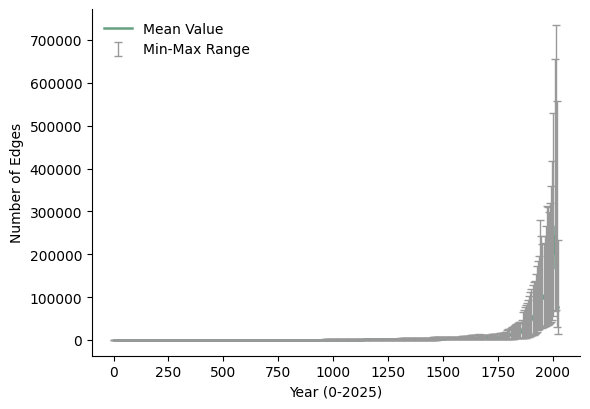

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CONFIG
# ============================================================
DATA_ROOT = r"tkgl_wikidata_crosslingual"   # <-- folder produced by the builder script
PAIRS     = ["en_fr", "en_fa", "en_zh", "en_ja"]

# ------------------------------------------------------------
# CORRECTED ASSUMPTION (previous version added +1900, which was wrong --
# it produced an axis running to year 3925, meaning raw ts values already
# reach ~2025 themselves). The evidence indicates 'ts' IS the real calendar
# year directly (with very old facts near ts=0/1 representing ancient
# dates), not an offset from 1900. If your data turns out to use a
# different convention after checking the printed year range below,
# adjust ts_to_year accordingly.
# ------------------------------------------------------------
def ts_to_year(ts):
    return ts

BIN_WIDTH = 5   # years per bin, matches the reference plot
# ============================================================


def load_years(filepath):
    df = pd.read_csv(filepath, sep="\t")
    return ts_to_year(df["ts"]).astype(int).tolist()


def discover_language_files(data_root, pairs):
    files = {}
    lang1, _ = pairs[0].split("_")
    files[lang1] = os.path.join(data_root, pairs[0], f"quadruples_{lang1}.tsv")
    for pair in pairs:
        _, other_lang = pair.split("_")
        files[other_lang] = os.path.join(data_root, pair, f"quadruples_{other_lang}.tsv")
    return files


def compute_binned_counts(years, bin_edges):
    counts, _ = np.histogram(years, bins=bin_edges)
    return counts


def plot_aggregate_edge_time_distribution(data_root, pairs, bin_width=5):
    lang_files = discover_language_files(data_root, pairs)
    print(f"Aggregating over {len(lang_files)} language KGs: {list(lang_files.keys())}")

    lang_years = {lang: load_years(path) for lang, path in lang_files.items()}

    all_years_flat = [y for years in lang_years.values() for y in years]
    min_year = min(all_years_flat)
    max_year = max(all_years_flat)

    bin_start = int(np.floor(min_year / bin_width) * bin_width)
    bin_end   = int(np.ceil((max_year + 1) / bin_width) * bin_width)
    bin_edges = np.arange(bin_start, bin_end + bin_width, bin_width)

    print(f"Year range in data: {min_year}-{max_year}  |  binned as {bin_start}-{bin_end}")

    counts_matrix = np.array([
        compute_binned_counts(years, bin_edges) for years in lang_years.values()
    ])

    mean_counts = counts_matrix.mean(axis=0)
    min_counts  = counts_matrix.min(axis=0)
    max_counts  = counts_matrix.max(axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2   # real calendar years

    fig, ax = plt.subplots(figsize=(6, 4.2))

    ax.step(bin_centers, mean_counts, where="mid",
            color="#66A182", linewidth=1.8, label="Mean Value")

    yerr_lower = mean_counts - min_counts
    yerr_upper = max_counts - mean_counts
    ax.errorbar(bin_centers, mean_counts, yerr=[yerr_lower, yerr_upper],
                fmt="none", ecolor="#999999", elinewidth=1, capsize=3,
                label="Min-Max Range")

    ax.set_xlabel(f"Year ({bin_start}-{bin_end})")
    ax.set_ylabel("Number of Edges")
    ax.legend(frameon=False, loc="upper left")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig("tkgl_wikidata_time_distribution.png", dpi=150,
                bbox_inches="tight", facecolor="white")
    print("Saved -> tkgl_wikidata_time_distribution.png")


if __name__ == "__main__":
    plot_aggregate_edge_time_distribution(DATA_ROOT, PAIRS, BIN_WIDTH)

Aggregating over 6 sources: ['fr_en:fr', 'fr_en:en', 'ja_en:ja', 'ja_en:en', 'zh_en:zh', 'zh_en:en']
Dropped 12 facts dated after 2025 (data artifacts)
Dropped 2192 facts before 1900 (ancient tail; set MIN_YEAR=None to disable)
Year range in data: 1900-2020  |  binned as 1900-2025
Saved -> dbp15k_time_distribution_aggregate.png


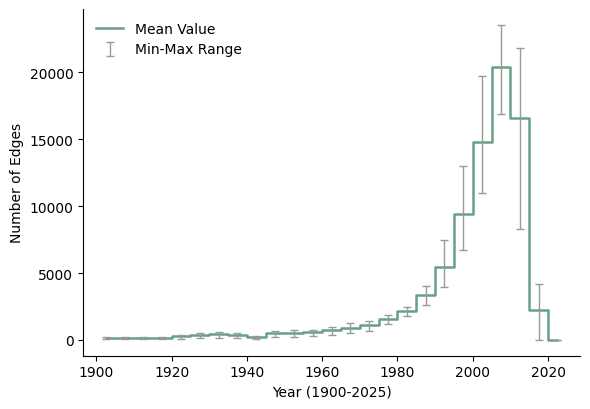

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CONFIG
# ============================================================
DATA_ROOT = r"D:\Proposal\Temporal Reasoning\TKG\EACTB-main\EACTB-main\dbp15k"  # <-- your DBP15K path
PAIRS     = ["fr_en", "ja_en", "zh_en"]

BIN_WIDTH = 5   # years per bin, matches the reference plot
MAX_YEAR  = 2025  # facts dated after this are dropped as data artifacts (see note below)

# A thin tail of very old facts can stretch the axis so far that the real
# action -- almost all the data -- gets compressed into a sliver at the
# right edge. Facts before MIN_YEAR are dropped from the plot (count
# reported below) rather than silently distorting the scale.
# Set to None to disable.
MIN_YEAR = 1900
# ============================================================


def load_time_id_map(filepath):
    """
    id -> year_int, or None for the '-inf' row (unknown/unspecified date).
    """
    year_map = {}
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) != 2:
                continue
            idx, val = parts
            year_map[int(idx)] = None if val == "-inf" else int(val)
    return year_map


def load_begin_years(triples_path, year_map):
    """
    triples_1 / triples_2 format: head_id rel_id tail_id begin_id end_id
    (tab-separated). Returns resolved begin years, dropping unknown (id 0).
    """
    df = pd.read_csv(
        triples_path, sep="\t", header=None,
        names=["head", "rel", "tail", "begin_id", "end_id"],
    )
    years = df["begin_id"].map(year_map)
    return years.dropna().astype(int).tolist()


def collect_all_sources(data_root, pairs):
    """
    DBP15K does NOT share a single global 'en' KG across pairs the way the
    earlier Wikidata12K split did -- each pair's triples_2 (the EN side) can
    be a different subgraph built specifically for that alignment task.
    So every triples_1 / triples_2 file across all pairs is treated as its
    own distinct source for the mean / min-max aggregation (6 sources total
    for 3 pairs), rather than assuming any of them are identical.
    """
    sources = {}
    for pair in pairs:
        lang1, lang2 = pair.split("_")
        year_map = load_time_id_map(os.path.join(data_root, pair, "time_id"))
        sources[f"{pair}:{lang1}"] = load_begin_years(
            os.path.join(data_root, pair, "triples_1"), year_map)
        sources[f"{pair}:{lang2}"] = load_begin_years(
            os.path.join(data_root, pair, "triples_2"), year_map)
    return sources


def compute_binned_counts(years, bin_edges):
    counts, _ = np.histogram(years, bins=bin_edges)
    return counts


def plot_aggregate_edge_time_distribution(data_root, pairs, bin_width=5, max_year=MAX_YEAR, min_year_cutoff=MIN_YEAR):
    sources = collect_all_sources(data_root, pairs)
    print(f"Aggregating over {len(sources)} sources: {list(sources.keys())}")

    # A handful of time_id entries are clearly data artifacts (e.g. 2808,
    # 19311, 19433) rather than real dates. Drop anything past max_year so
    # they don't stretch the axis into uselessness.
    dropped_future = 0
    dropped_ancient = 0
    for key, years in sources.items():
        before = len(years)
        years = [y for y in years if y <= max_year]
        dropped_future += before - len(years)

        if min_year_cutoff is not None:
            before2 = len(years)
            years = [y for y in years if y >= min_year_cutoff]
            dropped_ancient += before2 - len(years)

        sources[key] = years

    if dropped_future:
        print(f"Dropped {dropped_future} facts dated after {max_year} (data artifacts)")
    if dropped_ancient:
        print(f"Dropped {dropped_ancient} facts before {min_year_cutoff} "
              f"(ancient tail; set MIN_YEAR=None to disable)")

    all_years_flat = [y for years in sources.values() for y in years]
    if not all_years_flat:
        raise ValueError(
            f"No facts remain after applying MIN_YEAR={min_year_cutoff}/MAX_YEAR={max_year}. "
            f"Loosen these cutoffs and rerun."
        )
    min_year, max_year_actual = min(all_years_flat), max(all_years_flat)

    bin_start = int(np.floor(min_year / bin_width) * bin_width)
    bin_end   = int(np.ceil((max_year_actual + 1) / bin_width) * bin_width)
    bin_edges = np.arange(bin_start, bin_end + bin_width, bin_width)

    print(f"Year range in data: {min_year}-{max_year_actual}  |  binned as {bin_start}-{bin_end}")

    counts_matrix = np.array([
        compute_binned_counts(years, bin_edges) for years in sources.values()
    ])

    mean_counts = counts_matrix.mean(axis=0)
    min_counts  = counts_matrix.min(axis=0)
    max_counts  = counts_matrix.max(axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    fig, ax = plt.subplots(figsize=(6, 4.2))

    ax.step(bin_centers, mean_counts, where="mid",
            color="#66A182", linewidth=1.8, label="Mean Value")

    yerr_lower = mean_counts - min_counts
    yerr_upper = max_counts - mean_counts
    ax.errorbar(bin_centers, mean_counts, yerr=[yerr_lower, yerr_upper],
                fmt="none", ecolor="#999999", elinewidth=1, capsize=3,
                label="Min-Max Range")

    ax.set_xlabel(f"Year ({bin_start}-{bin_end})")
    ax.set_ylabel("Number of Edges")
    ax.legend(frameon=False, loc="upper left")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig("dbp15k_time_distribution_aggregate.png", dpi=150,
                bbox_inches="tight", facecolor="white")
    print("Saved -> dbp15k_time_distribution_aggregate.png")


if __name__ == "__main__":
    plot_aggregate_edge_time_distribution(DATA_ROOT, PAIRS, BIN_WIDTH, MAX_YEAR, MIN_YEAR)

In [ ]:
"""
KG-pair structural + temporal similarity/heterogeneity metrics
=================================================================

Works on the temporal DBP15K-style dataset layout (e.g. TEA-GNN / TREA / Time-aware
entity alignment benchmarks), where triples are QUADRUPLES with a timestamp id:

    fr_en/
        triples_1        # h_id \t r_id \t t_id \t time_id   (KG1, e.g. French)
        triples_2        # h_id \t r_id \t t_id \t time_id   (KG2, e.g. English)
        ent_ids_1        # id \t entity_uri                   (KG1)
        ent_ids_2        # id \t entity_uri                   (KG2)
        ref_ent_ids      # id1 \t id2                          (gold alignment, KG1 id -> KG2 id)
        time_id          # time_id \t date_string              (shared timestamp vocabulary)
        train / test / dev   # subsets of ref_ent_ids

The script auto-detects 3-column (static) vs 4-column (temporal) triples files,
so it also still works on plain DBP15K if you point it at that instead.

Metrics computed
-----------------
Structural (same as static case, computed on the h-r-t projection, ignoring time):
1. Basic stats: #entities, #relations, #triples, density
2. Degree distribution (in+out) per KG + Jensen-Shannon divergence between the two
3. Overlap ratio: fraction of entities that are covered by the gold alignment
4. Size similarity: 1 - |Δsize| / max(size1, size2)
5. Structure Similarity (Jiang et al. 2024 style): for every aligned entity pair (a, b),
   look at a's neighbors that themselves have a known counterpart via the alignment,
   map them into KG2's id space, and compute Jaccard overlap with b's actual neighbors.

Temporal (only computed if triples have a 4th timestamp column):
6. Temporal coverage: fraction of triples in each KG that carry a real (non-null) timestamp
7. Timestamp distribution per KG (histogram over time_id, or over parsed years if time_id
   maps to real dates) + Jensen-Shannon divergence between the two KGs' timestamp usage
8. Temporal span overlap: overlap of the [min_time, max_time] interval covered by each KG
9. Temporal structure similarity: like Structure Similarity above, but an aligned neighbor
   only counts toward the intersection if the edge timestamps also match (or are both
   unknown) -- this tells you whether structurally-aligned neighborhoods are ALSO
   temporally consistent, which matters a lot for temporal KG alignment specifically.

Usage
-----
    python kg_structural_similarity.py /path/to/fr_en
    python kg_structural_similarity.py /path/to/fr_en /path/to/ja_en /path/to/zh_en
"""

import sys
import os
from collections import defaultdict
import numpy as np


def read_triples(path):
    """Read a triples file. Auto-detects 3 columns (h, r, t) or 4 columns (h, r, t, time_id)."""
    triples = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split("\t")
            if len(parts) < 3:
                parts = line.strip().split()
            if len(parts) < 3:
                continue
            if len(parts) >= 4:
                h, r, t, time = parts[0], parts[1], parts[2], parts[3]
            else:
                h, r, t, time = parts[0], parts[1], parts[2], None
            triples.append((h, r, t, time))
    return triples


def read_time_id(path):
    """Read time_id file: time_id \t date_string. Returns dict id -> date string (or None if missing)."""
    if not os.path.exists(path):
        return {}
    mapping = {}
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split("\t")
            if len(parts) < 2:
                parts = line.strip().split()
            if len(parts) < 2:
                continue
            mapping[parts[0]] = parts[1]
    return mapping


def read_pairs(path):
    """Read a two-column id-pair file: id1 \t id2 (used for ent_ids, ref_ent_ids, train/test/dev)."""
    pairs = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split("\t")
            if len(parts) < 2:
                parts = line.strip().split()
            if len(parts) < 2:
                continue
            pairs.append((parts[0], parts[1]))
    return pairs


def build_graph(triples):
    """
    Build adjacency (undirected, for neighborhood/degree purposes).
    Also builds edge_time: (min(h,t), max(h,t)) -> set of timestamps seen on that edge,
    so temporal_structure_similarity can check timestamp consistency later.
    """
    neighbors = defaultdict(set)
    entities = set()
    relations = set()
    edge_time = defaultdict(set)
    for h, r, t, time in triples:
        neighbors[h].add(t)
        neighbors[t].add(h)
        entities.add(h)
        entities.add(t)
        relations.add(r)
        if time is not None:
            key = (h, t) if h <= t else (t, h)
            edge_time[key].add(time)
    return neighbors, entities, relations, edge_time


def degree_distribution(neighbors, entities, max_degree=50):
    """Return a normalized histogram of node degrees, bucketed 0..max_degree (last bucket = max_degree+)."""
    hist = np.zeros(max_degree + 1)
    for e in entities:
        d = len(neighbors.get(e, ()))
        idx = min(d, max_degree)
        hist[idx] += 1
    total = hist.sum()
    if total == 0:
        return hist
    return hist / total


def js_divergence(p, q, eps=1e-12):
    """Jensen-Shannon divergence between two discrete distributions (numpy arrays, same length)."""
    p = p + eps
    q = q + eps
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)

    def kl(a, b):
        return np.sum(a * np.log2(a / b))

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def structure_similarity(neighbors_1, neighbors_2, alignment):
    """
    Jiang-et-al.-style average neighbor structural similarity over aligned entity pairs.

    For each aligned pair (a in KG1, b in KG2):
      - take a's neighbors in KG1 that ALSO have a known alignment counterpart
      - map those neighbors into KG2's id space via the alignment
      - compute Jaccard similarity between that mapped set and b's real neighbor set in KG2
    Average over all aligned pairs that have at least one mappable neighbor on either side.
    """
    align_1_to_2 = dict(alignment)
    sims = []
    for a, b in alignment:
        na = neighbors_1.get(a, set())
        nb = neighbors_2.get(b, set())
        # map a's neighbors into KG2 space, keeping only those with a known alignment
        mapped_na = {align_1_to_2[n] for n in na if n in align_1_to_2}
        union = mapped_na | nb
        if not union:
            continue  # both sides isolated w.r.t. alignable neighbors, skip
        inter = mapped_na & nb
        sims.append(len(inter) / len(union))
    if not sims:
        return 0.0
    return float(np.mean(sims))


def temporal_coverage(triples):
    """Fraction of triples that carry a non-null timestamp."""
    if not triples:
        return 0.0
    with_time = sum(1 for (_, _, _, time) in triples if time is not None)
    return with_time / len(triples)


def timestamp_distribution(triples, all_timestamps):
    """Normalized histogram over a shared, sorted timestamp vocabulary. Untimed triples excluded."""
    idx = {ts: i for i, ts in enumerate(all_timestamps)}
    hist = np.zeros(len(all_timestamps))
    for (_, _, _, time) in triples:
        if time in idx:
            hist[idx[time]] += 1
    total = hist.sum()
    if total == 0:
        return hist
    return hist / total


def temporal_span_overlap(triples_1, triples_2):
    """Jaccard overlap of the SET of distinct timestamps actually used in each KG."""
    ts_1 = {time for (_, _, _, time) in triples_1 if time is not None}
    ts_2 = {time for (_, _, _, time) in triples_2 if time is not None}
    union = ts_1 | ts_2
    if not union:
        return 0.0
    return len(ts_1 & ts_2) / len(union)


def temporal_structure_similarity(neighbors_1, neighbors_2, edge_time_1, edge_time_2, alignment):
    """
    Like structure_similarity, but a neighbor only counts toward the intersection if the
    edge connecting it has a MATCHING timestamp on both sides (or neither side has
    timestamp info). Measures whether structurally-aligned neighborhoods are ALSO
    temporally consistent.
    """
    align_1_to_2 = dict(alignment)
    sims = []
    for a, b in alignment:
        na = neighbors_1.get(a, set())
        nb = neighbors_2.get(b, set())
        mapped_na = set()
        for n in na:
            if n not in align_1_to_2:
                continue
            mapped_n = align_1_to_2[n]
            key_1 = (a, n) if a <= n else (n, a)
            key_2 = (b, mapped_n) if b <= mapped_n else (mapped_n, b)
            t1 = edge_time_1.get(key_1, set())
            t2 = edge_time_2.get(key_2, set())
            if (not t1 and not t2) or (t1 & t2):
                mapped_na.add(mapped_n)
        union = mapped_na | nb
        if not union:
            continue
        inter = mapped_na & nb
        sims.append(len(inter) / len(union))
    if not sims:
        return 0.0
    return float(np.mean(sims))



def analyze_pair(folder):
    folder = folder.rstrip("/")
    name = os.path.basename(folder)

    triples_1 = read_triples(os.path.join(folder, "triples_1"))
    triples_2 = read_triples(os.path.join(folder, "triples_2"))
    ref = read_pairs(os.path.join(folder, "ref_ent_ids"))
    time_map = read_time_id(os.path.join(folder, "time_id"))

    is_temporal = any(t is not None for (_, _, _, t) in triples_1) or \
                  any(t is not None for (_, _, _, t) in triples_2)

    neighbors_1, entities_in_triples_1, relations_1, edge_time_1 = build_graph(triples_1)
    neighbors_2, entities_in_triples_2, relations_2, edge_time_2 = build_graph(triples_2)

    # Authoritative entity sets come from ent_ids_* (includes isolated entities
    # with zero triples, which build_graph would otherwise miss).
    ent_ids_1_path = os.path.join(folder, "ent_ids_1")
    ent_ids_2_path = os.path.join(folder, "ent_ids_2")
    if os.path.exists(ent_ids_1_path) and os.path.exists(ent_ids_2_path):
        entities_1 = {eid for eid, _ in read_pairs(ent_ids_1_path)}
        entities_2 = {eid for eid, _ in read_pairs(ent_ids_2_path)}
    else:
        entities_1, entities_2 = entities_in_triples_1, entities_in_triples_2

    n1, n2 = len(entities_1), len(entities_2)
    r1, r2 = len(relations_1), len(relations_2)
    t1, t2 = len(triples_1), len(triples_2)

    density_1 = t1 / (n1 * (n1 - 1)) if n1 > 1 else 0.0
    density_2 = t2 / (n2 * (n2 - 1)) if n2 > 1 else 0.0

    size_similarity = 1 - abs(n1 - n2) / max(n1, n2)

    overlap_ratio = len(ref) / min(n1, n2) if min(n1, n2) > 0 else 0.0

    hist_1 = degree_distribution(neighbors_1, entities_1)
    hist_2 = degree_distribution(neighbors_2, entities_2)
    jsd = js_divergence(hist_1, hist_2)

    struct_sim = structure_similarity(neighbors_1, neighbors_2, ref)

    print(f"\n===== {name} =====")
    print(f"KG1: {n1:>7} entities | {r1:>5} relations | {t1:>8} triples | density={density_1:.6f}")
    print(f"KG2: {n2:>7} entities | {r2:>5} relations | {t2:>8} triples | density={density_2:.6f}")
    print(f"Gold alignment size:        {len(ref)}")
    print(f"Overlap ratio:              {overlap_ratio:.4f}")
    print(f"Size similarity:            {size_similarity:.4f}")
    print(f"Degree-dist JS divergence:  {jsd:.4f}  (0 = identical distributions, 1 = maximally different)")
    print(f"Structure similarity:       {struct_sim:.4f}  (higher = aligned entities sit in more similar neighborhoods)")

    result = {
        "name": name,
        "n1": n1, "n2": n2, "r1": r1, "r2": r2, "t1": t1, "t2": t2,
        "density_1": density_1, "density_2": density_2,
        "overlap_ratio": overlap_ratio,
        "size_similarity": size_similarity,
        "js_divergence": jsd,
        "structure_similarity": struct_sim,
        "degree_hist_1": hist_1.tolist(),
        "degree_hist_2": hist_2.tolist(),
        "is_temporal": is_temporal,
    }

    if is_temporal:
        cov_1 = temporal_coverage(triples_1)
        cov_2 = temporal_coverage(triples_2)

        all_timestamps = sorted(time_map.keys()) if time_map else sorted(
            {t for (_, _, _, t) in triples_1 + triples_2 if t is not None}
        )
        ts_hist_1 = timestamp_distribution(triples_1, all_timestamps)
        ts_hist_2 = timestamp_distribution(triples_2, all_timestamps)
        ts_jsd = js_divergence(ts_hist_1, ts_hist_2) if all_timestamps else 0.0

        span_overlap = temporal_span_overlap(triples_1, triples_2)
        temp_struct_sim = temporal_structure_similarity(
            neighbors_1, neighbors_2, edge_time_1, edge_time_2, ref
        )

        print(f"\n--- Temporal metrics ---")
        print(f"Temporal coverage KG1/KG2:  {cov_1:.4f} / {cov_2:.4f}  (fraction of triples with a timestamp)")
        print(f"Timestamp-dist JS divergence: {ts_jsd:.4f}  (0 = same timestamp usage pattern)")
        print(f"Temporal span overlap:      {span_overlap:.4f}  (Jaccard of distinct timestamps used)")
        print(f"Temporal structure similarity: {temp_struct_sim:.4f}  "
              f"(structure similarity requiring matching edge timestamps)")

        result.update({
            "temporal_coverage_1": cov_1,
            "temporal_coverage_2": cov_2,
            "timestamp_js_divergence": ts_jsd,
            "temporal_span_overlap": span_overlap,
            "temporal_structure_similarity": temp_struct_sim,
        })

    return result


if __name__ == "__main__":
    if len(sys.argv) < 2:
        print("Usage: python kg_structural_similarity.py <folder1> [folder2] [folder3] ...")
        sys.exit(1)

    results = [analyze_pair(folder) for folder in sys.argv[1:]]

    if len(results) > 1:
        any_temporal = any(r.get("is_temporal") for r in results)
        print("\n===== Summary across datasets =====")
        if any_temporal:
            print(f"{'dataset':<10}{'overlap':>10}{'size_sim':>10}{'JS_div':>10}{'struct_sim':>12}"
                  f"{'temp_JSD':>12}{'temp_span':>12}{'temp_struct':>13}")
            for r in results:
                if r.get("is_temporal"):
                    print(f"{r['name']:<10}{r['overlap_ratio']:>10.4f}{r['size_similarity']:>10.4f}"
                          f"{r['js_divergence']:>10.4f}{r['structure_similarity']:>12.4f}"
                          f"{r['timestamp_js_divergence']:>12.4f}{r['temporal_span_overlap']:>12.4f}"
                          f"{r['temporal_structure_similarity']:>13.4f}")
                else:
                    print(f"{r['name']:<10}{r['overlap_ratio']:>10.4f}{r['size_similarity']:>10.4f}"
                          f"{r['js_divergence']:>10.4f}{r['structure_similarity']:>12.4f}"
                          f"{'--':>12}{'--':>12}{'--':>13}")
        else:
            print(f"{'dataset':<10}{'overlap':>10}{'size_sim':>10}{'JS_div':>10}{'struct_sim':>12}")
            for r in results:
                print(f"{r['name']:<10}{r['overlap_ratio']:>10.4f}{r['size_similarity']:>10.4f}"
                  f"{r['js_divergence']:>10.4f}{r['structure_similarity']:>12.4f}")

# TKGL-Wikidata

In [2]:
import requests

def get_label(qid, languages=["en", "fr", "de", "es"]):
    url = "https://www.wikidata.org/w/api.php"
    params = {
        "action": "wbgetentities",
        "ids": qid,
        "props": "labels",
        "languages": "|".join(languages),
        "format": "json"
    }
    headers = {
        'User-Agent': 'MyTKGProject/1.0 (your.email@example.com)'  # ← Important!
    }
    
    response = requests.get(url, params=params, headers=headers)
    
    print("Status:", response.status_code)        # Debug
    print("Content-Type:", response.headers.get('Content-Type'))
    
    if response.status_code != 200:
        print("Error text:", response.text[:500])
        return {"error": f"HTTP {response.status_code}"}
    
    data = response.json()
    # ... rest of your code
    
    entity = data["entities"].get(qid)
    if entity and "labels" in entity:
        labels = {lang: entity["labels"][lang]["value"] 
                 for lang in languages if lang in entity["labels"]}
        return labels
    return {"error": "No labels found"}

# Test
print(get_label("Q33155"))

Status: 200
Content-Type: application/json; charset=utf-8
{'en': 'Rome–Civita Castellana–Viterbo railway', 'fr': 'ligne urbaine Roma-Civita Castellana-Viterbe', 'de': 'Bahnstrecke Rom–Civita Castellana–Viterbo'}


In [3]:
print(get_label("Q331755"))


Status: 200
Content-Type: application/json; charset=utf-8
{'en': 'Sverre of Norway', 'fr': 'Sverre de Norvège', 'de': 'Sverre', 'es': 'Sverre I de Noruega'}


In [4]:
print(get_label("Q1294765"))

Status: 200
Content-Type: application/json; charset=utf-8
{'en': 'Monarch of Norway', 'fr': 'Monarchie norvégienne', 'de': 'Norwegische Monarchie', 'es': 'Monarca de Noruega'}


In [6]:
print(get_label("Q553893"))

Status: 200
Content-Type: application/json; charset=utf-8
{'en': 'Charles Emmanuel, Landgrave of Hesse-Rotenburg', 'fr': 'Charles-Emmanuel de Hesse-Rheinfels-Rotenbourg', 'de': 'Karl Emanuel', 'es': 'Carlos Manuel de Hesse-Rotenburg'}


In [7]:
print(get_label("Q63407940"))

Status: 200
Content-Type: application/json; charset=utf-8
{'fr': 'landgrave de Hesse-Rheinfels-Rotenbourg'}


In [5]:
import requests

def get_property_label(pid, languages=["en", "fr", "de", "es"]):
    """Get labels for a Wikidata property (P39, P348, etc.)"""
    url = "https://www.wikidata.org/w/api.php"
    params = {
        "action": "wbgetentities",
        "ids": pid,           # e.g. "P39"
        "props": "labels",
        "languages": "|".join(languages),
        "format": "json"
    }
    headers = {
        'User-Agent': 'MyTKGProject/1.0 (your.email@example.com)'   # ← Very important!
    }
    
    response = requests.get(url, params=params, headers=headers)
    
    if response.status_code != 200:
        print("Error:", response.status_code)
        print(response.text[:300])
        return {"error": f"HTTP {response.status_code}"}
    
    data = response.json()
    entity = data["entities"].get(pid)
    
    if entity and "labels" in entity:
        labels = {lang: entity["labels"][lang]["value"] 
                 for lang in languages if lang in entity["labels"]}
        return labels
    return {"error": "No labels found"}

# Test with one from your screenshot
print(get_property_label("P39"))

{'en': 'position held', 'fr': 'fonction', 'de': 'öffentliches Amt oder Stellung', 'es': 'cargo ocupado'}


# Creating a new cross-lingual TKG from Wikidata

## filtering valid quadruples from tkgl-wikidata dataset

In [10]:
import pandas as pd
import requests
import time
from tqdm import tqdm

# ================== CONFIG ==================
FILE_PATH = r'C:\Users\Partiran\Desktop\TKG\tkgl-wikidata_edgelist.csv'
LANGUAGES = ["en"]           # Start with English only
MIN_LANGS_REQUIRED = 1
MAX_QIDS = 2000              # Small but reasonable for testing
# ===========================================

print("Loading dataset...")
df = pd.read_csv(FILE_PATH)
print(f"Original rows: {len(df)} | Time range: {df['ts'].min()}–{df['ts'].max()}")

all_qids = pd.concat([df['head'], df['tail']]).unique()
sample_qids = list(all_qids)[:MAX_QIDS]
print(f"Sampling {len(sample_qids)} QIDs...")

def get_multi_lang_labels(qids, languages=LANGUAGES):
    results = {}
    chunks = [qids[i:i+50] for i in range(0, len(qids), 50)]   # ← Much smaller chunks (safe limit)
    
    for i, chunk in enumerate(tqdm(chunks, desc="Fetching labels")):
        ids_str = "|".join(chunk)
        url = "https://www.wikidata.org/w/api.php"
        params = {
            "action": "wbgetentities",
            "ids": ids_str,
            "props": "labels",
            "languages": "|".join(languages),
            "format": "json"
        }
        headers = {'User-Agent': 'CrossLingualTKG-Debug/1.0 (your.email@example.com)'}
        
        try:
            resp = requests.get(url, params=params, headers=headers, timeout=15)
            # print(f"Chunk {i+1} Status: {resp.status_code}")   # uncomment if needed
            
            if resp.status_code == 200:
                data = resp.json()
                
                # Handle error response from Wikidata
                if "error" in data:
                    print(f"API Error: {data['error']}")
                    continue
                
                if "entities" not in data:
                    print("No 'entities' key in response")
                    continue
                
                for qid in chunk:
                    entity = data["entities"].get(qid)
                    if entity and "labels" in entity:
                        lang_labels = {lang: entity["labels"][lang]["value"] 
                                     for lang in languages if lang in entity["labels"]}
                        if lang_labels:
                            results[qid] = lang_labels
        except Exception as e:
            print(f"Exception in chunk {i+1}: {e}")
        
        time.sleep(0.6)   # polite delay
    
    return results

print("Starting label fetch...")
qid_multi_labels = get_multi_lang_labels(sample_qids)

print(f"\nSuccessfully labeled QIDs: {len(qid_multi_labels)}")

valid_qids = {qid: labels for qid, labels in qid_multi_labels.items() 
              if len(labels) >= MIN_LANGS_REQUIRED}

print(f"Valid QIDs: {len(valid_qids)}")

# Filter the dataframe
valid_mask = (df['head'].isin(valid_qids)) & (df['tail'].isin(valid_qids))
df_filtered = df[valid_mask].copy()

print(f"Remaining quadruples: {len(df_filtered)}")

if len(df_filtered) > 0:
    for lang in LANGUAGES:
        df_filtered[f'head_label_{lang}'] = df_filtered['head'].map(
            lambda q: valid_qids.get(q, {}).get(lang, q))
        df_filtered[f'tail_label_{lang}'] = df_filtered['tail'].map(
            lambda q: valid_qids.get(q, {}).get(lang, q))
    
    df_filtered.to_csv("tkgl_filtered_en.csv", index=False)
    print("✅ Saved tkgl_filtered_en.csv")
    print("\nPreview:")
    print(df_filtered.head(5))
else:
    print("Still empty - please paste the new console output.")

Loading dataset...
Original rows: 9856203 | Time range: 0–2024
Sampling 2000 QIDs...
Starting label fetch...


Fetching labels: 100%|█████████████████████████████████████████████████████████████████| 40/40 [01:11<00:00,  1.79s/it]



Successfully labeled QIDs: 1949
Valid QIDs: 1949
Remaining quadruples: 35443
✅ Saved tkgl_filtered_en.csv

Preview:
    ts    head     tail relation_type head_label_en        tail_label_en
42   6  Q47492    Q2277           P17     Gaza City         Roman Empire
51   7  Q47492    Q2277           P17     Gaza City         Roman Empire
61   8  Q47492    Q2277           P17     Gaza City         Roman Empire
72   9  Q47492    Q2277           P17     Gaza City         Roman Empire
77   9   Q1411  Q236259           P26      Claudius  Plautia Urgulanilla


In [4]:
for each in os.listdir():
    if each.endswith('csv'):
        print(each)

tkgl_wikidata_filtered_en_fr.csv


In [1]:
import pandas as pd
import requests
import time
from tqdm import tqdm

df = pd.read_csv("tkgl_filtered_en.csv")
print(f"Loaded {len(df)} rows")

# Get unique QIDs from the filtered file
all_qids = pd.concat([df['head'], df['tail']]).unique()
print(f"Unique QIDs: {len(all_qids)}")

LANGUAGES = ["fr"]          # Change to "de", "es", etc. if you prefer

def get_multi_lang_labels(qids, languages=LANGUAGES):
    results = {}
    chunks = [qids[i:i+50] for i in range(0, len(qids), 50)]
    
    for chunk in tqdm(chunks, desc=f"Fetching {languages[0]} labels"):
        ids_str = "|".join(chunk)
        url = "https://www.wikidata.org/w/api.php"
        params = {
            "action": "wbgetentities",
            "ids": ids_str,
            "props": "labels",
            "languages": "|".join(languages),
            "format": "json"
        }
        headers = {'User-Agent': 'CrossLingualTKG/1.0 (your.email@example.com)'}
        
        try:
            resp = requests.get(url, params=params, headers=headers, timeout=15)
            if resp.status_code == 200:
                data = resp.json()
                if "error" not in data and "entities" in data:
                    for qid in chunk:
                        entity = data["entities"].get(qid)
                        if entity and "labels" in entity:
                            lang_labels = {lang: entity["labels"][lang]["value"] 
                                         for lang in languages if lang in entity["labels"]}
                            if lang_labels:
                                results[qid] = lang_labels
        except:
            pass
        time.sleep(0.6)
    
    return results

print("Fetching second language labels...")
second_lang_labels = get_multi_lang_labels(all_qids)

print(f"Successfully got {len(second_lang_labels)} labels in {LANGUAGES[0]}")

# Merge into the dataframe
lang = LANGUAGES[0]
df[f'head_label_{lang}'] = df['head'].map(lambda q: second_lang_labels.get(q, {}).get(lang, None))
df[f'tail_label_{lang}'] = df['tail'].map(lambda q: second_lang_labels.get(q, {}).get(lang, None))

# Keep only rows that have labels in BOTH languages
df_cross = df.dropna(subset=[f'head_label_{lang}', f'tail_label_{lang}']).copy()

print(f"Final cross-lingual quadruples: {len(df_cross)}")

df_cross.to_csv(f"tkgl_cross_en_{lang}.csv", index=False)
print(f"✅ Saved tkgl_cross_en_{lang}.csv")

Loaded 35443 rows
Unique QIDs: 207
Fetching second language labels...


Fetching fr labels: 100%|████████████████████████████████████████████████████████████████| 5/5 [00:12<00:00,  2.56s/it]


Successfully got 187 labels in fr
Final cross-lingual quadruples: 30282
✅ Saved tkgl_cross_en_fr.csv


# Splitting and creating cross-linguual RKG

In [2]:
import pandas as pd
import numpy as np

# ================== CONFIG ==================
INPUT_FILE = "tkgl_cross_en_fr.csv"
LANG_A = "en"
LANG_B = "fr"
SHARED_RATIO = 0.25      # 20-30% shared entities is reasonable
NUM_SEEDS = 1000
RANDOM_SEED = 42
# ===========================================

np.random.seed(RANDOM_SEED)

print("Loading cross-lingual dataset...")
df = pd.read_csv(INPUT_FILE)
print(f"Loaded {len(df)} quadruples")

# 1. Split ENTITIES
all_entities = pd.concat([df['head'], df['tail']]).unique()
np.random.shuffle(all_entities)

n = len(all_entities)
n_shared = int(SHARED_RATIO * n)
n_rest = n - n_shared
n_a_only = n_rest // 2
n_b_only = n_rest - n_a_only

shared_ents = set(all_entities[:n_shared])
a_only = set(all_entities[n_shared : n_shared + n_a_only])
b_only = set(all_entities[n_shared + n_a_only:])

ents_a = shared_ents | a_only
ents_b = shared_ents | b_only

print(f"Shared entities: {len(shared_ents)}")
print(f"{LANG_A}-only: {len(a_only)}")
print(f"{LANG_B}-only: {len(b_only)}")

# 2. Assign quadruples (both endpoints must belong to the KG)
in_a = df['head'].isin(ents_a) & df['tail'].isin(ents_a)
in_b = df['head'].isin(ents_b) & df['tail'].isin(ents_b)

df_a = df[in_a].copy()
df_b = df[in_b].copy()

dropped = len(df) - len(df_a) - len(df_b)
print(f"TKG_{LANG_A}: {len(df_a)} facts")
print(f"TKG_{LANG_B}: {len(df_b)} facts")
print(f"Dropped facts (cross-KG): {dropped}")

# 3. True overlapping entities for seeds
present_a = set(pd.concat([df_a['head'], df_a['tail']]).unique())
present_b = set(pd.concat([df_b['head'], df_b['tail']]).unique())
true_overlap = list(present_a & present_b)

print(f"True overlapping entities: {len(true_overlap)}")

num_seeds = min(NUM_SEEDS, len(true_overlap))
seed_entities = np.random.choice(true_overlap, num_seeds, replace=False)

# 4. Build label maps (more robust)
label_map_a = {}
label_map_b = {}

for _, row in df.iterrows():
    h = row['head']
    t = row['tail']
    label_map_a[h] = row.get(f'head_label_{LANG_A}', h)
    label_map_a[t] = row.get(f'tail_label_{LANG_A}', t)
    label_map_b[h] = row.get(f'head_label_{LANG_B}', h)
    label_map_b[t] = row.get(f'tail_label_{LANG_B}', t)

# 5. Save
df_a.to_csv(f"tkg_{LANG_A}.csv", index=False)
df_b.to_csv(f"tkg_{LANG_B}.csv", index=False)

seeds_df = pd.DataFrame({
    'entity_id': seed_entities,
    f'label_{LANG_A}': [label_map_a.get(e, e) for e in seed_entities],
    f'label_{LANG_B}': [label_map_b.get(e, e) for e in seed_entities],
})

seeds_df.to_csv(f"seed_alignments_{num_seeds}_{LANG_A}_{LANG_B}.csv", index=False)

print(f"\n✅ Done! Seed alignments: {num_seeds}")

Loading cross-lingual dataset...
Loaded 30282 quadruples
Shared entities: 45
en-only: 68
fr-only: 68
TKG_en: 4599 facts
TKG_fr: 18357 facts
Dropped facts (cross-KG): 7326
True overlapping entities: 19

✅ Done! Seed alignments: 19
